# NFL Combine Tracking and Rookie Playing Time
### Research sample for the Toronto Blue Jays Baseball Research questionnaire

**Research question:** Do movement features from NFL Combine 40-yard-dash tracking improve prediction of rookie-season offensive/defensive playing time beyond traditional Combine measurements and draft information?

**Approach:** Restrict to the **2025 draft class** (to avoid unequal cumulative career exposure) and to players with 40-yard-dash tracking, then compare models on the **same players and cross-validation splits**.

**Outcome:** At least 100 offensive + defensive snaps in the available career-success table. This is an exploratory proxy for meaningful rookie playing time, **not an independent measure of ability**.

**Important caveat:** The outcome file contains cumulative career values. For 2025 draftees, it is treated here as a first-season proxy, conditional on the competition's data snapshot. Confirm the snapshot's cutoff before using the conclusion in a real decision.

In [1]:
import io
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Put the Kaggle ZIP alongside this notebook, or update the path.
ZIP_PATH = Path("nfl-big-data-bowl-2027.zip")
if not ZIP_PATH.exists() and Path("/mnt/data/nfl-big-data-bowl-2027.zip").exists():
    ZIP_PATH = Path("/mnt/data/nfl-big-data-bowl-2027.zip")
if not ZIP_PATH.exists():
    raise FileNotFoundError("Place nfl-big-data-bowl-2027.zip next to this notebook.")

def load_csv(filename):
    with zipfile.ZipFile(ZIP_PATH) as archive:
        matches = [name for name in archive.namelist()
                   if name.endswith("/" + filename) or name == filename]
        if len(matches) != 1:
            raise ValueError(f"Expected one match for {filename}, found {matches}")
        with archive.open(matches[0]) as f:
            return pd.read_csv(f)

players = load_csv("players.csv")
results = load_csv("combine_results.csv")
tracking = load_csv("combine_tracking.csv")
outcomes = load_csv("player_career_successes.csv")
for name, table in [("players", players),("results",results),
                    ("tracking",tracking),("outcomes",outcomes)]:
    print(name, table.shape)

players (510, 10)
results (510, 18)
tracking (463189, 14)
outcomes (510, 9)


## 1. Validate joins and create movement features

Only the 40-yard dash is used for tracking features. The CSV provides speed (`s`) and acceleration (`a`) at multiple frames per attempt. We aggregate the available frames per player. These aggregate features may reflect tracking duration and attempt composition, so they require validation before operational use.

**Avoiding data leakage:** All features originate at the Combine or draft, before the career outcome. Imputation and standardization are fitted **inside** each training fold.

In [2]:
assert players.nfl_id.is_unique and results.nfl_id.is_unique and outcomes.nfl_id.is_unique
assert {"s","a","drill_name","entity_type","nfl_id"}.issubset(tracking.columns)
dash = tracking.loc[
    tracking["drill_name"].eq("FORTY_YARD_DASH")
    & tracking["entity_type"].eq("PLAYER")
    & tracking["draft_year"].eq(2025)
].copy()
for col in ["s","a"]:
    dash[col] = pd.to_numeric(dash[col], errors="coerce")

features = dash.groupby("nfl_id", as_index=False).agg(
    tracking_peak_speed=("s","max"),
    tracking_mean_speed=("s","mean"),
    tracking_peak_accel=("a","max"),
    tracking_mean_accel=("a","mean"),
    tracking_speed_sd=("s","std"),
)

joined = (players.query("draft_year == 2025")
          .merge(results.drop(columns=["draft_year"]), on="nfl_id", validate="one_to_one")
          .merge(outcomes, on="nfl_id", validate="one_to_one")
          .merge(features, on="nfl_id", validate="one_to_one"))

joined["rookie_snaps"] = (joined["career_offensive_snaps"]
                         + joined["career_defensive_snaps"])
joined["meaningful_playing_time"] = (joined["rookie_snaps"] >= 100).astype(int)
assert not joined.nfl_id.duplicated().any()
assert joined["rookie_snaps"].ge(0).all()
print("Players in study:", len(joined))
print("Reached 100 snaps:", joined.meaningful_playing_time.sum())
print("Missing value fractions (top):")
print(joined.isna().mean().sort_values(ascending=False).head(10))

Players in study: 133
Reached 100 snaps: 68
Missing value fractions (top):
bench_reps                 0.676692
three_cone                 0.639098
short_shuttle              0.593985
draft_pick_within_round    0.270677
draft_round                0.270677
draft_overall_pick         0.270677
broad_jump                 0.142857
vertical                   0.097744
nfl_id                     0.000000
college_name               0.000000
dtype: float64


## 2. Exploratory analysis
The 100-snap threshold is a practical binary outcome. Its choice is arbitrary; future work should test sensitivity to the threshold and alternative outcomes such as snaps per active game.

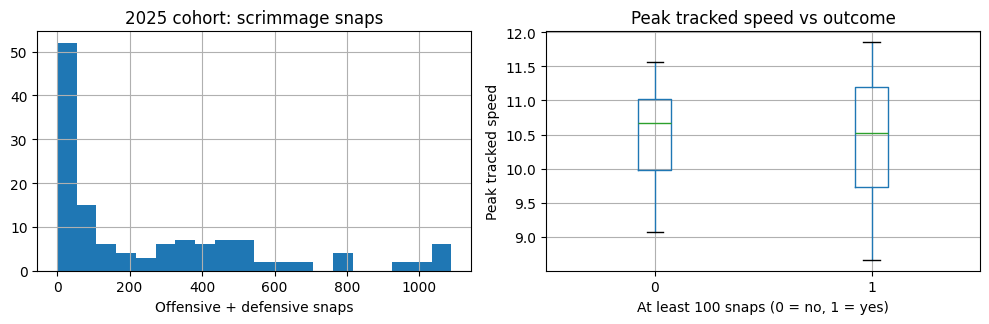

In [3]:
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
joined["rookie_snaps"].hist(bins=20,ax=axes[0])
axes[0].set_title("2025 cohort: scrimmage snaps")
axes[0].set_xlabel("Offensive + defensive snaps")
joined.boxplot(column="tracking_peak_speed",by="meaningful_playing_time",ax=axes[1])
axes[1].set_xlabel("At least 100 snaps (0 = no, 1 = yes)")
axes[1].set_ylabel("Peak tracked speed")
axes[1].set_title("Peak tracked speed vs outcome")
fig.suptitle("")
plt.tight_layout()
plt.show()

## 3. Repeated cross-validation

A model using traditional Combine features and draft pick is compared to the **same logistic regression algorithm** with five added movement features. A random forest with tracking features is an exploratory nonlinear comparator.

Three repetitions of stratified 5-fold CV reduce dependence on one random split. Results are descriptive; repeated folds are correlated and should **not** be treated as 15 independent studies. ROC-AUC measures ranking, average precision measures precision/recall performance, and Brier score assesses probabilistic accuracy (lower is better).

In [4]:
traditional_cols = [
    "nfl_position","draft_overall_pick","combine_height","combine_weight",
    "ten_yd_split","forty","vertical","broad_jump","three_cone",
    "short_shuttle","bench_reps"
]
movement_cols = [
    "tracking_peak_speed","tracking_mean_speed",
    "tracking_peak_accel","tracking_mean_accel","tracking_speed_sd"
]
assert set(traditional_cols + movement_cols).issubset(joined.columns)

def build_pipeline(cols, algorithm="logistic"):
    numeric = [col for col in cols if col != "nfl_position"]
    preprocess = ColumnTransformer([
        ("numeric", Pipeline([
            ("impute",SimpleImputer(strategy="median", add_indicator=True)),
            ("scale",StandardScaler())
        ]), numeric),
        ("position",OneHotEncoder(handle_unknown="ignore"),["nfl_position"])
    ])
    classifier = (LogisticRegression(C=0.5, max_iter=3000)
                  if algorithm == "logistic" else
                  RandomForestClassifier(n_estimators=150, min_samples_leaf=5,
                                         random_state=42, n_jobs=1))
    return Pipeline([("preprocess",preprocess),("model",classifier)])

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
specs = [
    ("Traditional logistic", traditional_cols, "logistic"),
    ("Traditional + tracking logistic", traditional_cols + movement_cols,"logistic"),
    ("Traditional + tracking forest", traditional_cols + movement_cols,"forest")
]
scores = {}
for label,cols,algo in specs:
    result = cross_validate(
        build_pipeline(cols, algo), joined[cols], joined["meaningful_playing_time"],
        cv=cv, scoring=["roc_auc","average_precision","neg_brier_score"], n_jobs=1
    )
    scores[label] = {
        "ROC-AUC": result["test_roc_auc"].mean(),
        "Average precision": result["test_average_precision"].mean(),
        "Brier score": -result["test_neg_brier_score"].mean()
    }
summary = pd.DataFrame(scores).T.round(3)
print(summary.to_string())
print("\nTracking incremental ROC-AUC vs traditional:",
      round(scores["Traditional + tracking logistic"]["ROC-AUC"] -
            scores["Traditional logistic"]["ROC-AUC"],3))

                                 ROC-AUC  Average precision  Brier score
Traditional logistic               0.803              0.828        0.196
Traditional + tracking logistic    0.791              0.820        0.200
Traditional + tracking forest      0.770              0.786        0.200

Tracking incremental ROC-AUC vs traditional: -0.013


## 4. Interpret results and limitations

A negative incremental change means the added tracked-movement features did not improve **this tested model, cohort and target**. It does not establish that tracking has no scouting value.

Limitations include small sample size, exclusion of players without 40-yard tracking, heterogeneous positions, missing drill results, draft pick being a powerful signal of opportunity as well as quality, uncertain snapshot cutoff, and the arbitrary 100-snap target. Better tests would use a confirmed fixed first-season dataset, position-specific models, more realistic athletic movement features, and multi-year prospective validation.

In [5]:
comparison = summary[["ROC-AUC","Average precision","Brier score"]].copy()
print(comparison.to_string())
print("\nStudy N:",len(joined), "positive cases:",int(joined.meaningful_playing_time.sum()))
print("Interpretation: Do not claim that tracking helps unless it improves held-out metrics.")

                                 ROC-AUC  Average precision  Brier score
Traditional logistic               0.803              0.828        0.196
Traditional + tracking logistic    0.791              0.820        0.200
Traditional + tracking forest      0.770              0.786        0.200

Study N: 133 positive cases: 68
Interpretation: Do not claim that tracking helps unless it improves held-out metrics.
